# Heisenberg model in emu-mps, driven by a pulser sequence

emu-mps can simulate a general Heisenberg (XYZ) Hamiltonian

$$
H(t) = \sum_j \frac{\Omega_j(t)}{2}\big[\cos\phi_j X_j + \sin\phi_j Y_j\big] - \sum_j \Delta_j(t)\, n_j
 + \sum_{i<j} \big( J^{xx}_{ij} X_iX_j + J^{yy}_{ij} Y_iY_j + J^{zz}_{ij} Z_iZ_j \big)
$$

with Pauli matrices $X, Y, Z$, $n = |d\rangle\langle d| = (1-Z)/2$, frequencies in rad/µs and times in ns.
Isotropic Heisenberg is $J^{xx}=J^{yy}=J^{zz}=J$; with $\Omega=\Delta=0$ only the interaction is left.

Pulser has no Heisenberg channel, so the workflow is:
1. build a normal pulser `Sequence` on the XY (`mw_global`) channel: register, pulses, noise model;
2. let emu-base's `PulserData` sample it into a `SequenceData` (Ω, Δ, φ, time grid, XY couplings, Lindblad operators);
3. replace its interaction matrix by a `3 x n x n` stack `[Jxx, Jyy, Jzz]`, which switches emu-mps to Heisenberg mode;
4. run it with `MPSBackend._run_from_sequence_data`.

Every emu-mps result is checked against an exact dense simulation: state vector without noise,
Lindblad master equation with noise. We do this for a **pulsed** sequence and a **free** (no pulse) one.

In [1]:
import dataclasses
import logging
import random
from functools import reduce

import matplotlib.pyplot as plt
import numpy as np
import pulser
import torch
from pulser.devices import MockDevice

from emu_base import PulserData
from emu_mps import MPS, MPSBackend, MPSConfig, Occupation, StateResult

dtype = torch.complex128
random.seed(0)  # emu-mps quantum jumps use python's `random`
torch.manual_seed(0)

## 1. Register and pulser sequences

A chain of 6 atoms, 18 µm apart. Two sequences on the global microwave (XY) channel of `MockDevice`:
- **pulsed**: Blackman π-pulse with a linear detuning ramp from -3 to 3 rad/µs;
- **free**: a delay of the same duration, i.e. $\Omega=\Delta=0$, pure Heisenberg dynamics.

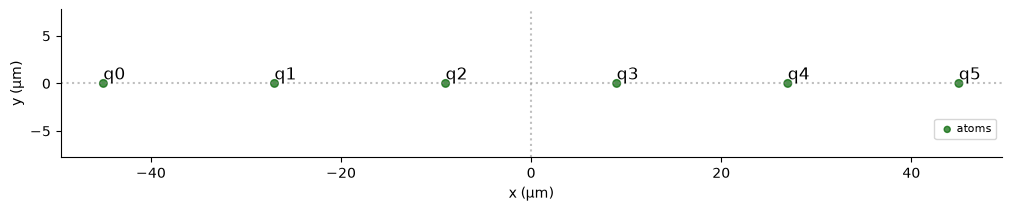

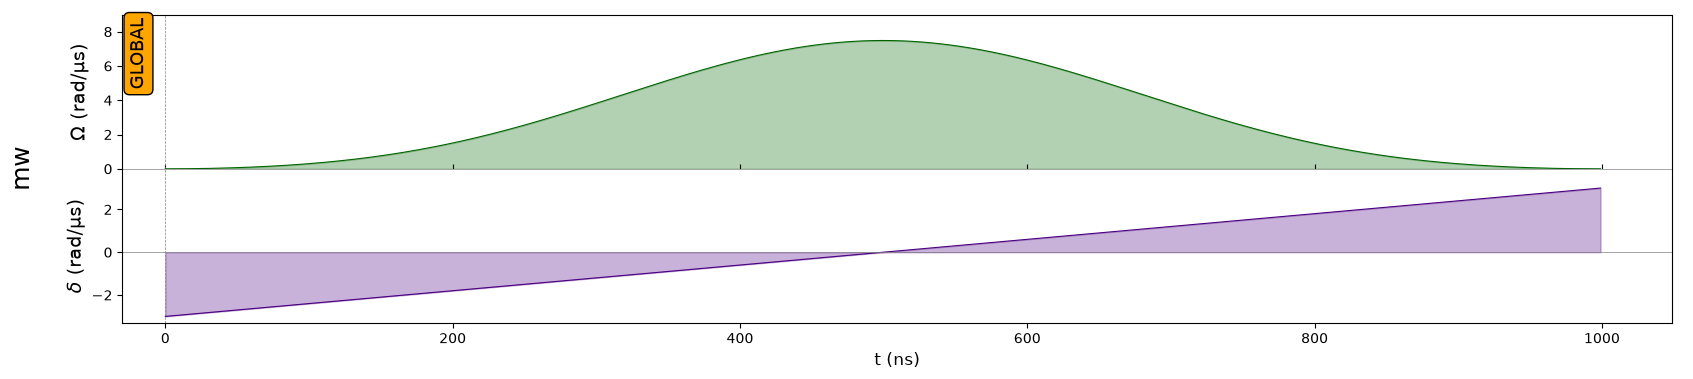

In [2]:
n, T, dt = 6, 1000, 10  # qubits, duration (ns), emu-mps time step (ns)
reg = pulser.Register.rectangle(1, n, spacing=18.0, prefix="q")


def make_sequence(pulsed):
    seq = pulser.Sequence(reg, MockDevice)
    seq.declare_channel("mw", "mw_global")
    if pulsed:
        pulse = pulser.Pulse(
            amplitude=pulser.BlackmanWaveform(T, area=np.pi),
            detuning=pulser.RampWaveform(T, -3.0, 3.0),
            phase=0.0,
        )
        seq.add(pulse, "mw")
    else:
        seq.delay(T, "mw")
    return seq


sequences = {"pulsed": make_sequence(True), "free": make_sequence(False)}
reg.draw()
sequences["pulsed"].draw()

## 2. From pulser to a Heisenberg `SequenceData`

`PulserData` does the pulser sampling exactly as `MPSBackend.run` would. Its interaction matrix is the pulser XY
stack `[C3/r³ (1 - 3cos²θ), 0]`; we keep the dipolar couplings $J_{ij} = C_3(1-3\cos^2\theta_{ij})/r_{ij}^3$
and scale them per term with `anisotropy` = `(Jxx, Jyy, Jzz) / J`. `(1, 1, 1)` is isotropic,
e.g. `(1, 0.7, 1.3)` gives an XYZ model. A pulser `NoiseModel` passed here becomes `lindblad_ops`.

/Users/i.sokolov/Code/emulators/ci/emu_mps/emu_mps/mps_config.py:111: UserWarning: 'MPSConfig' was initialized without any observables. The corresponding emulation results will be empty.
  super().__init__(


eigenstates ['u', 'd'], omega (100, 6), 100 steps of 10 ns
nearest-neighbour coupling: 6.222 rad/µs


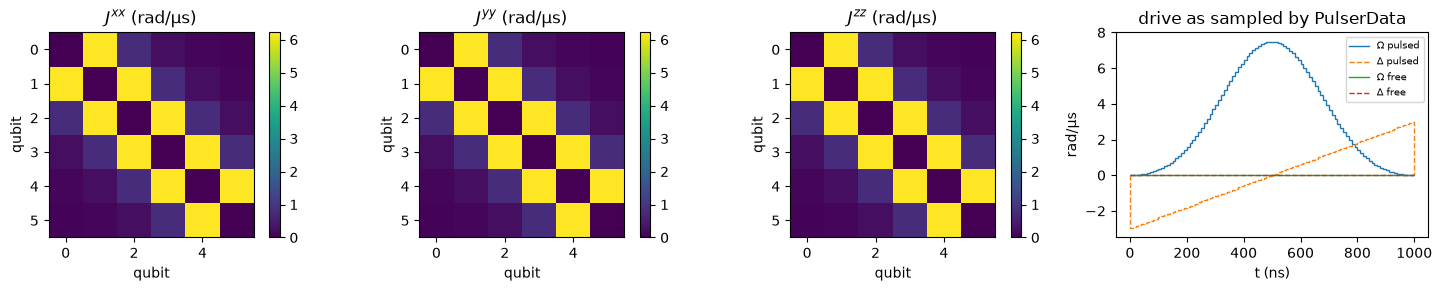

In [3]:
anisotropy = torch.tensor([1.0, 1.0, 1.0], dtype=torch.float64)


def heisenberg_sequence_data(seq, noise_model=None):
    config = MPSConfig(dt=dt, noise_model=noise_model) if noise_model else MPSConfig(dt=dt)
    (sd,) = PulserData(sequence=seq, config=config, dt=dt).get_sequences()
    J = anisotropy[:, None, None] * sd.interaction_matrix(0.0)[0]  # (3, n, n)
    return dataclasses.replace(sd, interaction_matrix=lambda t: J)  # 3 x n x n => Heisenberg


seq_data = {name: heisenberg_sequence_data(seq) for name, seq in sequences.items()}

sd = seq_data["pulsed"]
J = sd.interaction_matrix(0.0)
print(f"eigenstates {sd.eigenstates}, omega {tuple(sd.omega.shape)}, {len(sd.target_times) - 1} steps of {dt} ns")
print(f"nearest-neighbour coupling: {J[0, 0, 1]:.3f} rad/µs")

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, Jk, name in zip(axes, J, ("$J^{xx}$", "$J^{yy}$", "$J^{zz}$")):
    fig.colorbar(ax.imshow(Jk, cmap="viridis"), ax=ax)
    ax.set_title(name + " (rad/µs)"); ax.set_xlabel("qubit"); ax.set_ylabel("qubit")
for name, s in seq_data.items():
    axes[3].stairs(s.omega[:, 0].real, s.target_times, label=rf"$\Omega$ {name}")
    axes[3].stairs(s.delta[:, 0].real, s.target_times, label=rf"$\Delta$ {name}", linestyle="--")
axes[3].set_xlabel("t (ns)"); axes[3].set_ylabel("rad/µs"); axes[3].legend(fontsize=7)
axes[3].set_title("drive as sampled by PulserData")
fig.tight_layout()

## 3. Exact references

Dense $2^n$ simulations driven by the very same `SequenceData` arrays: `omega[k]`, `delta[k]`, `phi[k]` are constant
on `[target_times[k], target_times[k+1]]`. The initial state is the Néel state $|udud\dots\rangle$ and we record
$\langle n_j \rangle(t)$, the population of $|d\rangle$ (what emu-mps' `Occupation` measures).

In [4]:
X = torch.tensor([[0, 1], [1, 0]], dtype=dtype)
Y = torch.tensor([[0, -1j], [1j, 0]], dtype=dtype)
Z = torch.tensor([[1, 0], [0, -1]], dtype=dtype)
Nd = torch.tensor([[0, 0], [0, 1]], dtype=dtype)


def op(single, i):
    # single-qubit operator on qubit i; qubit 0 is the most significant bit
    return reduce(torch.kron, [single if k == i else torch.eye(2, dtype=dtype) for k in range(n)])


N_ops = [op(Nd, j) for j in range(n)]
neel_bits = "".join(str(j % 2) for j in range(n))


def hamiltonians(sd):
    # one dense H per time step
    J = sd.interaction_matrix(0.0)
    H_int = sum(
        J[a, i, j] * op(P, i) @ op(P, j)
        for a, P in enumerate((X, Y, Z))
        for i in range(n)
        for j in range(i + 1, n)
    )
    w, d, p = sd.omega.real, sd.delta.real, sd.phi.real
    return [
        H_int + sum(
            w[k, j] / 2 * (torch.cos(p[k, j]) * op(X, j) + torch.sin(p[k, j]) * op(Y, j)) - d[k, j] * N_ops[j]
            for j in range(n)
        )
        for k in range(len(w))
    ]


def exact_state_dynamics(sd):
    psi = torch.zeros(2**n, dtype=dtype)
    psi[int(neel_bits, 2)] = 1.0
    occ = [torch.stack([torch.vdot(psi, Nj @ psi).real for Nj in N_ops])]
    for H, t0, t1 in zip(hamiltonians(sd), sd.target_times, sd.target_times[1:]):
        psi = torch.linalg.matrix_exp(-1j * H * (t1 - t0) / 1000) @ psi  # µs
        occ.append(torch.stack([torch.vdot(psi, Nj @ psi).real for Nj in N_ops]))
    return torch.stack(occ), psi


def exact_lindblad_dynamics(sd, n_sub=10):
    # RK4 on rho' = -i[H, rho] + sum_k L rho L^+ - 1/2 {L^+ L, rho}
    Ls = [op(L, j) for L in sd.lindblad_ops for j in range(n)]
    LdL = sum(L.mH @ L for L in Ls)

    def rhs(rho, H_eff):
        out = -1j * (H_eff @ rho - rho @ H_eff.mH)
        for L in Ls:
            out += L @ rho @ L.mH
        return out

    rho = torch.zeros(2**n, 2**n, dtype=dtype)
    rho[int(neel_bits, 2), int(neel_bits, 2)] = 1.0
    occ = [torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops])]
    purity = [torch.trace(rho @ rho).real]
    for H, t0, t1 in zip(hamiltonians(sd), sd.target_times, sd.target_times[1:]):
        H_eff, h = H - 0.5j * LdL, (t1 - t0) / 1000 / n_sub
        for _ in range(n_sub):
            k1 = rhs(rho, H_eff)
            k2 = rhs(rho + h / 2 * k1, H_eff)
            k3 = rhs(rho + h / 2 * k2, H_eff)
            k4 = rhs(rho + h * k3, H_eff)
            rho = rho + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        occ.append(torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops]))
        purity.append(torch.trace(rho @ rho).real)
    return torch.stack(occ), torch.stack(purity)

## 4. emu-mps vs exact, pulsed and free

Qubit reordering is off so qubit indices match the exact simulation.

In [5]:
def run_mps(sd, *observables):
    # Néel product state; built from factors since MPS.from_state_amplitudes doesn't accept the XY basis ("u", "d")
    neel = MPS([torch.tensor([[[1.0 - int(b)], [float(b)]]], dtype=dtype) for b in neel_bits], eigenstates=sd.eigenstates)
    config = MPSConfig(
        observables=list(observables),
        initial_state=neel,
        optimize_qubit_ordering=False,
        precision=1e-9,
        log_level=logging.WARN,
    )
    return MPSBackend._run_from_sequence_data(sd, config)


def occupations(results):
    return torch.stack([torch.as_tensor(o) for o in results.occupation])


exact, mps_occ = {}, {}
for name, sd in seq_data.items():
    eval_times = [(t - sd.target_times[0]) / (sd.target_times[-1] - sd.target_times[0]) for t in sd.target_times]
    res = run_mps(sd, Occupation(evaluation_times=eval_times), StateResult(evaluation_times=[1.0]))
    exact[name], psi_exact = exact_state_dynamics(sd)
    mps_occ[name] = occupations(res)
    psi_mps = reduce(lambda a, b: torch.tensordot(a, b, dims=1), res.state[-1].factors).reshape(-1).cpu()
    print(
        f"{name:>6}: final fidelity {abs(torch.vdot(psi_exact, psi_mps)) ** 2:.8f}, "
        f"max |<n_j> error| {(mps_occ[name] - exact[name]).abs().max():.1e}, "
        f"max bond dim {res.state[-1].get_max_bond_dim()}"
    )

emu-mps allows only {'energy', 'energy_second_moment', 'statistics', 'correlation_matrix', 'bitstrings', 'energy_variance', 'occupation'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


pulsed: final fidelity 0.99998697, max |<n_j> error| 1.1e-03, max bond dim 8
emu-mps allows only {'energy', 'energy_second_moment', 'statistics', 'correlation_matrix', 'bitstrings', 'energy_variance', 'occupation'} observables with `optimize_qubit_ordering = True`. you provided unsupported {'state'} using `optimize_qubit_ordering = False` instead.


  free: final fidelity 0.99998425, max |<n_j> error| 1.2e-03, max bond dim 8


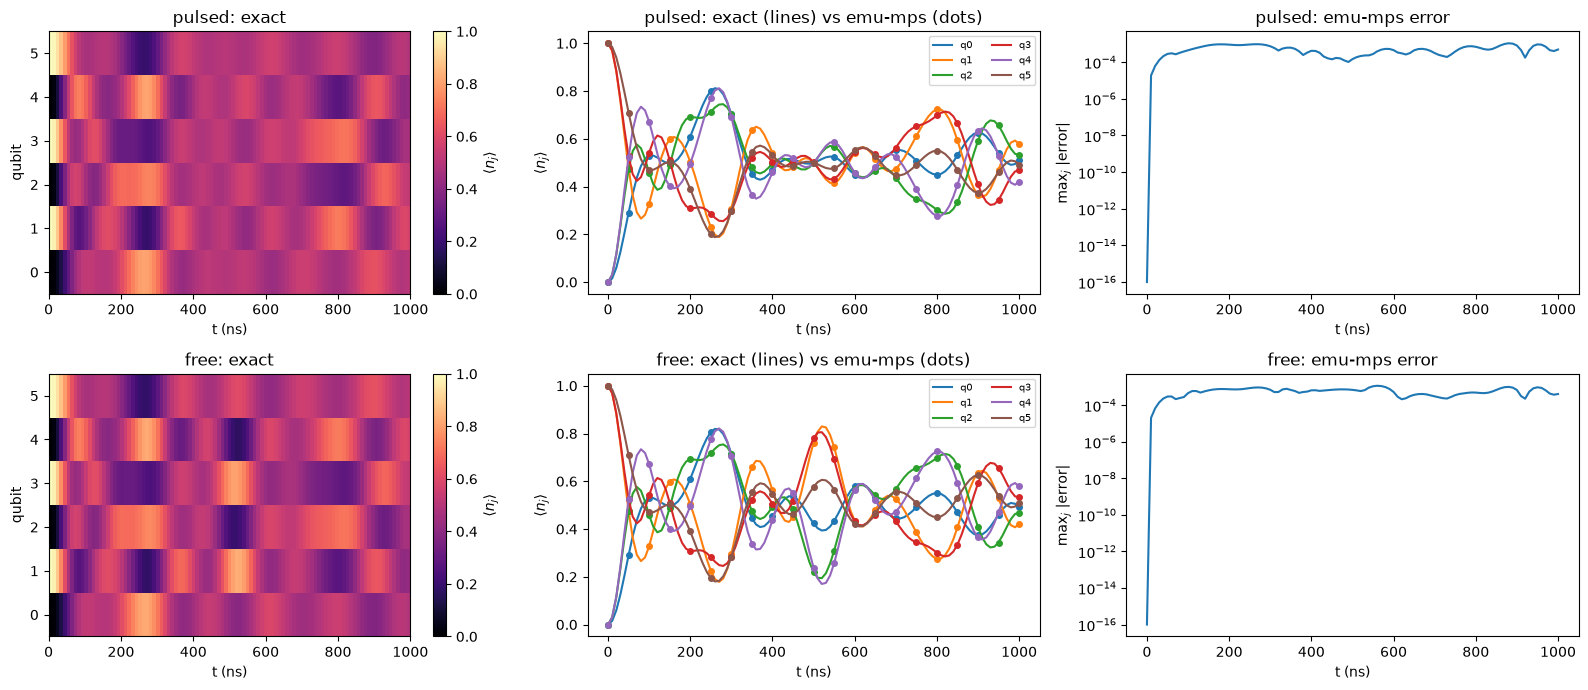

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for row, name in zip(axes, seq_data):
    times = np.array(seq_data[name].target_times)
    im = row[0].imshow(exact[name].T, aspect="auto", origin="lower", extent=(0, T, -0.5, n - 0.5),
                       cmap="magma", vmin=0, vmax=1)
    fig.colorbar(im, ax=row[0], label=r"$\langle n_j \rangle$")
    row[0].set_title(f"{name}: exact"); row[0].set_xlabel("t (ns)"); row[0].set_ylabel("qubit")
    for j in range(n):
        (line,) = row[1].plot(times, exact[name][:, j], label=f"q{j}")
        row[1].plot(times[::5], mps_occ[name][::5, j], "o", color=line.get_color(), ms=4)
    row[1].set_title(f"{name}: exact (lines) vs emu-mps (dots)")
    row[1].set_xlabel("t (ns)"); row[1].set_ylabel(r"$\langle n_j \rangle$"); row[1].legend(ncol=2, fontsize=7)
    row[2].semilogy(times, (mps_occ[name] - exact[name]).abs().max(dim=1).values + 1e-16)
    row[2].set_title(f"{name}: emu-mps error"); row[2].set_xlabel("t (ns)"); row[2].set_ylabel(r"max$_j$ |error|")
fig.tight_layout()

The residual error is the TDVP time-splitting error of the long-range couplings: it scales as $dt^2$
(halving `dt` reduces it ~4x); with nearest-neighbour couplings it is at machine precision.

## 5. Small noise from a pulser `NoiseModel`

The noise model goes through `PulserData` like for any pulser simulation and arrives as single-qubit Lindblad operators.
emu-mps runs the Monte Carlo wave-function method: one call = one trajectory, so we average over trajectories and
compare with the exact Lindblad solution.

In [7]:
noise_model = pulser.NoiseModel(dephasing_rate=0.2, depolarizing_rate=0.1)  # 1/µs
n_traj = 50

noisy = {}
for name, seq in sequences.items():
    sd = heisenberg_sequence_data(seq, noise_model)
    eval_times = [(t - sd.target_times[0]) / (sd.target_times[-1] - sd.target_times[0]) for t in sd.target_times]
    traj = torch.stack([occupations(run_mps(sd, Occupation(evaluation_times=eval_times))) for _ in range(n_traj)])
    occ_lindblad, purity = exact_lindblad_dynamics(sd)
    noisy[name] = dict(mc=traj.mean(0), mc_err=traj.std(0) / n_traj**0.5, lindblad=occ_lindblad, purity=purity)
    print(
        f"{name:>6}: {len(sd.lindblad_ops)} Lindblad ops, max |MC - Lindblad| {(traj.mean(0) - occ_lindblad).abs().max():.3f} "
        f"(MC std. error up to {noisy[name]['mc_err'].max():.3f}), "
        f"max |noisy - noiseless| {(occ_lindblad - exact[name]).abs().max():.3f}, final purity {purity[-1]:.3f}"
    )

pulsed: 4 Lindblad ops, max |MC - Lindblad| 0.051 (MC std. error up to 0.024), max |noisy - noiseless| 0.120, final purity 0.156


  free: 4 Lindblad ops, max |MC - Lindblad| 0.052 (MC std. error up to 0.026), max |noisy - noiseless| 0.120, final purity 0.162


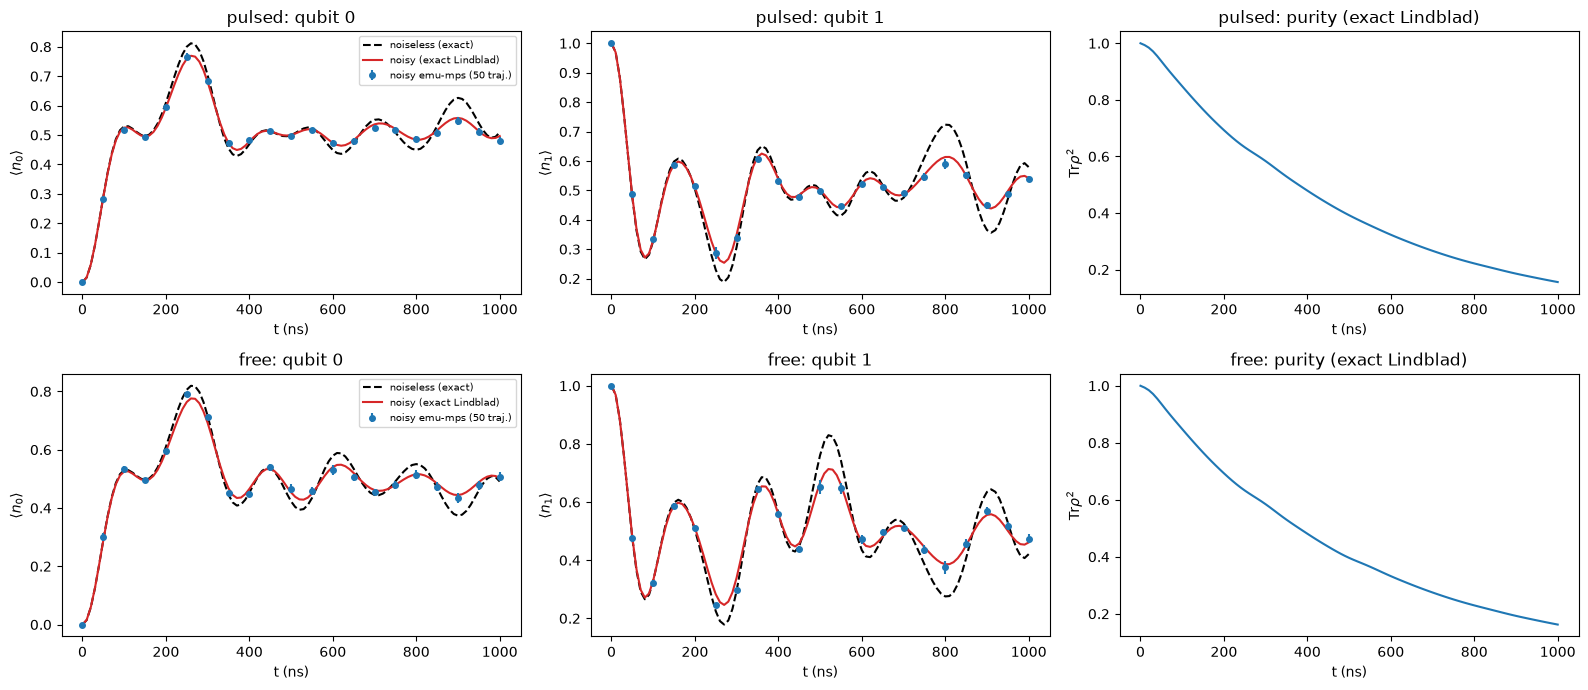

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for row, name in zip(axes, sequences):
    times = np.array(seq_data[name].target_times)
    r = noisy[name]
    for ax, j in zip(row[:2], (0, 1)):
        ax.plot(times, exact[name][:, j], "k--", label="noiseless (exact)")
        ax.plot(times, r["lindblad"][:, j], "C3", label="noisy (exact Lindblad)")
        ax.errorbar(times[::5], r["mc"][::5, j], yerr=r["mc_err"][::5, j], fmt="o", color="C0", ms=4,
                    label=f"noisy emu-mps ({n_traj} traj.)")
        ax.set_title(f"{name}: qubit {j}"); ax.set_xlabel("t (ns)"); ax.set_ylabel(rf"$\langle n_{j} \rangle$")
    row[0].legend(fontsize=7)
    row[2].plot(times, r["purity"])
    row[2].set_title(f"{name}: purity (exact Lindblad)"); row[2].set_xlabel("t (ns)"); row[2].set_ylabel(r"Tr$\rho^2$")
fig.tight_layout()

**Reading the plots.** In both the pulsed and the free case the Monte Carlo average follows the exact Lindblad
solution within its statistical error (which shrinks as $1/\sqrt{n_{traj}}$), and both deviate visibly from the
noiseless curve. The per-qubit rates are small (0.1-0.2 /µs), but the purity of the 6-qubit state decays roughly as
the product over qubits, so it drops well below 1 within 1 µs. Lower the rates or `T` for a gentler effect.